# Comparación de configuraciones



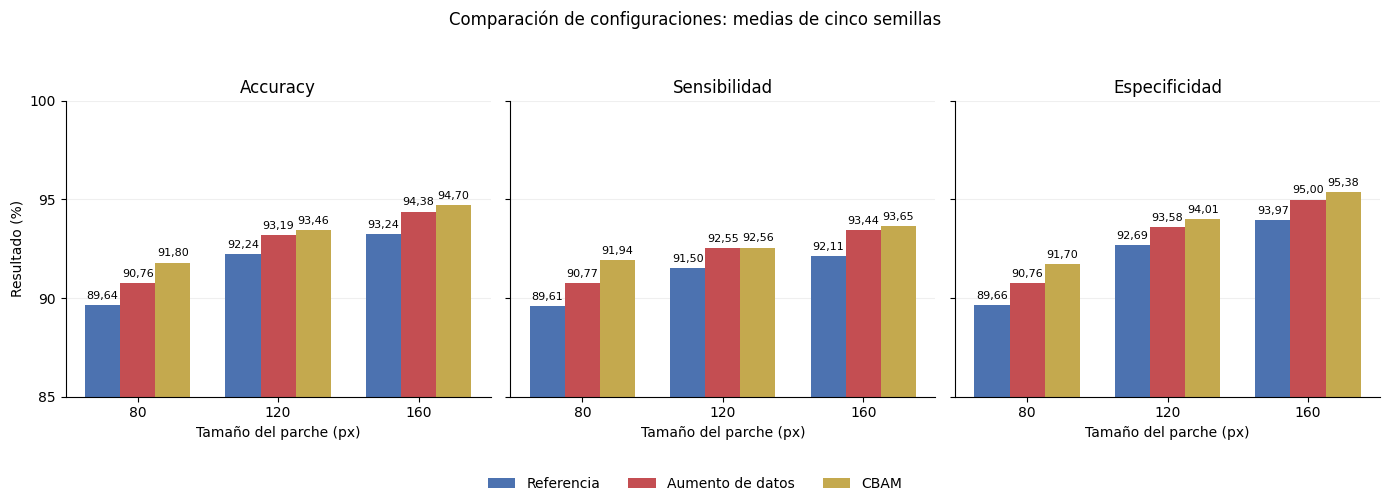

/workspace/results/figuras_comparacion/comparacion_barras.png

/workspace/results/figuras_comparacion/comparacion_barras.pdf

In [9]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import FileLink, display

CLASS_COLORS   = {"base": "#4C72B0", "data": "#C44E52", "cbam": "#C4A94E"}

# Localizar la carpeta del proyecto.
raiz = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "results" / "baseline_80px_results.json").exists()
)

tamanos = [80, 120, 160]
configuraciones = [
    ("baseline", "Referencia",  CLASS_COLORS["base"]),
    ("augmentation", "Aumento de datos", CLASS_COLORS["data"]),
    ("cbam", "CBAM", CLASS_COLORS["cbam"]),
]
metricas = [
    ("accuracy", "Accuracy"),
    ("recall_abnormal", "Sensibilidad"),
    ("specificity", "Especificidad"),
]

# Leer los resultados.
resultados = {}
for nombre, _, _ in configuraciones:
    for tamano in tamanos:
        ruta = raiz / "results" / f"{nombre}_{tamano}px_results.json"
        with ruta.open(encoding="utf-8") as archivo:
            resultados[nombre, tamano] = json.load(archivo)[
                "aggregated_across_seeds"
            ]

# Crear tres gráficas de barras.
fig, ejes = plt.subplots(1, 3, figsize=(14, 5), sharey=True)
x = np.arange(len(tamanos))
ancho = 0.25

for eje, (metrica, titulo) in zip(ejes, metricas):
    for i, (nombre, etiqueta, color) in enumerate(configuraciones):
        medias = [
            100 * resultados[nombre, t][metrica]["mean"]
            for t in tamanos
        ]

        barras = eje.bar(
            x + (i - 1) * ancho,
            medias,
            width=ancho,
            label=etiqueta,
            color=color,
        )

        eje.bar_label(
            barras,
            labels=[f"{valor:.2f}".replace(".", ",") for valor in medias],
            padding=3,
            fontsize=8,
        )

    eje.set_title(titulo)
    eje.set_xticks(x, [str(t) for t in tamanos])
    eje.set_xlabel("Tamaño del parche (px)")
    eje.set_ylim(85, 100)
    eje.set_yticks(np.arange(85, 101, 5))
    eje.grid(axis="y", alpha=0.2)
    eje.set_axisbelow(True)
    eje.spines[["top", "right"]].set_visible(False)

ejes[0].set_ylabel("Resultado (%)")

manejadores, etiquetas = ejes[0].get_legend_handles_labels()
fig.legend(
    manejadores, etiquetas,
    loc="lower center",
    ncol=3,
    frameon=False,
)

fig.suptitle("Comparación de configuraciones: medias de cinco semillas")
fig.tight_layout(rect=(0, 0.09, 1, 0.94))

# Guardar la figura.
salida = raiz / "results" / "figuras_comparacion"
salida.mkdir(parents=True, exist_ok=True)

for extension in ("png", "pdf"):
    fig.savefig(
        salida / f"comparacion_barras.{extension}",
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

plt.show()

# Mostrar enlaces de descarga en Jupyter.
import os

for extension in ("png", "pdf"):
    ruta = salida / f"comparacion_barras.{extension}"
    display(FileLink(os.path.relpath(ruta, Path.cwd())))

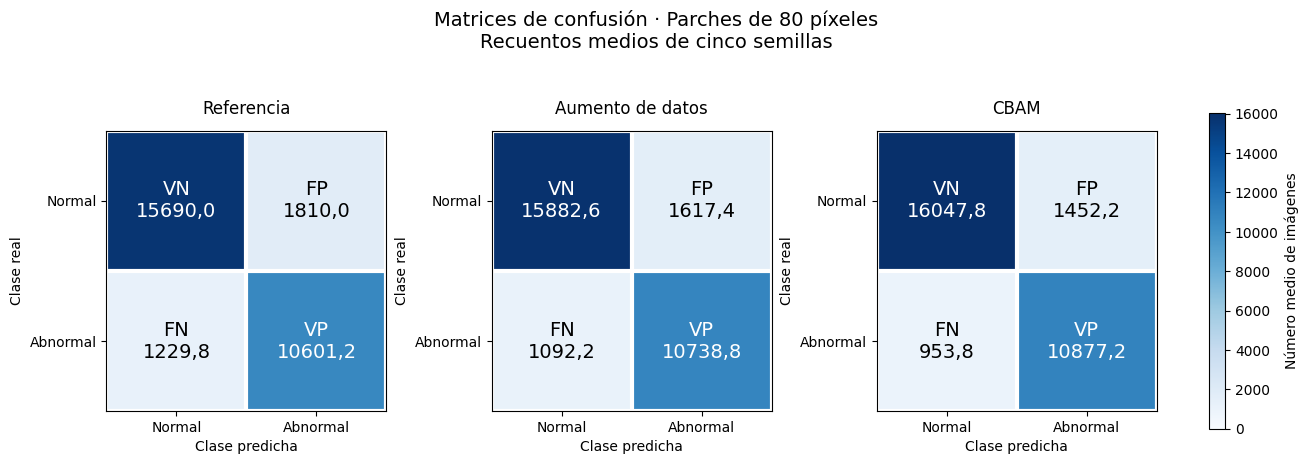

/workspace/results/figuras_comparacion/matrices_confusion_80px.png

/workspace/results/figuras_comparacion/matrices_confusion_80px.pdf

In [12]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import FileLink, display

# Cambia este valor para representar otro tamaño.
RESOLUCION = 80

raiz = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "results" / "baseline_80px_results.json").exists()
)

configuraciones = [
    ("baseline", "Referencia"),
    ("augmentation", "Aumento de datos"),
    ("cbam", "CBAM"),
]

# Calcular la matriz media de cada configuración.
# Orden:
#              Predicción
#              Normal  Abnormal
# Real Normal    VN       FP
# Real Abnormal  FN       VP
matrices = []

for nombre, titulo in configuraciones:
    ruta = raiz / "results" / f"{nombre}_{RESOLUCION}px_results.json"

    with ruta.open(encoding="utf-8") as archivo:
        datos = json.load(archivo)

    matrices_semillas = []

    for ejecucion in datos["per_seed"]:
        cm = ejecucion["test_metrics"]["confusion_matrix"]

        matrices_semillas.append([
            [cm["tn"], cm["fp"]],
            [cm["fn"], cm["tp"]],
        ])

    matrices.append(np.mean(matrices_semillas, axis=0))

# Escala de color común para las tres matrices.
maximo = max(matriz.max() for matriz in matrices)

fig, ejes = plt.subplots(
    1, 3,
    figsize=(13, 4.8),
    layout="constrained",
)

nombres_celdas = [
    ["VN", "FP"],
    ["FN", "VP"],
]

for eje, matriz, (_, titulo) in zip(
    ejes, matrices, configuraciones
):
    imagen = eje.imshow(
        matriz,
        cmap="Blues",
        vmin=0,
        vmax=maximo,
    )

    # Mostrar el tipo de resultado y su recuento medio.
    for fila in range(2):
        for columna in range(2):
            valor = matriz[fila, columna]
            texto = f"{valor:.1f}".replace(".", ",")

            eje.text(
                columna,
                fila,
                f"{nombres_celdas[fila][columna]}\n{texto}",
                ha="center",
                va="center",
                fontsize=14,
                color="white" if valor > maximo / 2 else "black",
            )

    eje.set_title(titulo, fontsize=12, pad=12)
    eje.set_xlabel("Clase predicha")
    eje.set_ylabel("Clase real")

    eje.set_xticks([0, 1], ["Normal", "Abnormal"])
    eje.set_yticks([0, 1], ["Normal", "Abnormal"])

    # Dibujar los límites de las cuatro celdas.
    eje.set_xticks([-0.5, 0.5, 1.5], minor=True)
    eje.set_yticks([-0.5, 0.5, 1.5], minor=True)
    eje.grid(which="minor", color="white", linewidth=3)
    eje.tick_params(which="minor", bottom=False, left=False)

fig.colorbar(
    imagen,
    ax=ejes,
    shrink=0.75,
    label="Número medio de imágenes",
)

fig.suptitle(
    f"Matrices de confusión · Parches de {RESOLUCION} píxeles\n"
    "Recuentos medios de cinco semillas",
    fontsize=14,
)

# Guardar la figura en PNG y PDF.
salida = raiz / "results" / "figuras_comparacion"
salida.mkdir(parents=True, exist_ok=True)

for extension in ("png", "pdf"):
    ruta = salida / f"matrices_confusion_{RESOLUCION}px.{extension}"

    fig.savefig(
        ruta,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

plt.show()

# Enlaces para descargar los archivos desde Jupyter.
for extension in ("png", "pdf"):
    ruta = salida / f"matrices_confusion_{RESOLUCION}px.{extension}"
    display(FileLink(os.path.relpath(ruta, Path.cwd())))

ValueError: 'Reeds' is not a valid value for cmap; supported values are 'Accent', 'Accent_r', 'Blues', 'Blues_r', 'BrBG', 'BrBG_r', 'BuGn', 'BuGn_r', 'BuPu', 'BuPu_r', 'CMRmap', 'CMRmap_r', 'Dark2', 'Dark2_r', 'GnBu', 'GnBu_r', 'Grays', 'Greens', 'Greens_r', 'Greys', 'Greys_r', 'OrRd', 'OrRd_r', 'Oranges', 'Oranges_r', 'PRGn', 'PRGn_r', 'Paired', 'Paired_r', 'Pastel1', 'Pastel1_r', 'Pastel2', 'Pastel2_r', 'PiYG', 'PiYG_r', 'PuBu', 'PuBuGn', 'PuBuGn_r', 'PuBu_r', 'PuOr', 'PuOr_r', 'PuRd', 'PuRd_r', 'Purples', 'Purples_r', 'RdBu', 'RdBu_r', 'RdGy', 'RdGy_r', 'RdPu', 'RdPu_r', 'RdYlBu', 'RdYlBu_r', 'RdYlGn', 'RdYlGn_r', 'Reds', 'Reds_r', 'Set1', 'Set1_r', 'Set2', 'Set2_r', 'Set3', 'Set3_r', 'Spectral', 'Spectral_r', 'Wistia', 'Wistia_r', 'YlGn', 'YlGnBu', 'YlGnBu_r', 'YlGn_r', 'YlOrBr', 'YlOrBr_r', 'YlOrRd', 'YlOrRd_r', 'afmhot', 'afmhot_r', 'autumn', 'autumn_r', 'binary', 'binary_r', 'bone', 'bone_r', 'brg', 'brg_r', 'bwr', 'bwr_r', 'cividis', 'cividis_r', 'cool', 'cool_r', 'coolwarm', '

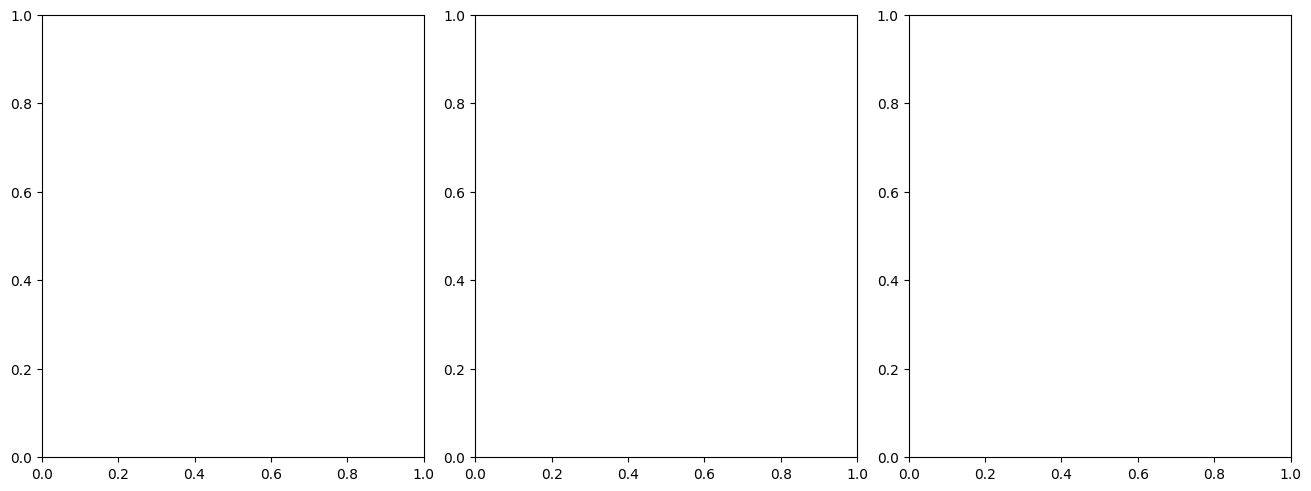

In [ ]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import FileLink, display

# Opciones: "baseline", "augmentation" o "cbam".
CONFIGURACION = "cbam"

nombres = {
    "baseline": "Referencia",
    "augmentation": "Aumento de datos",
    "cbam": "CBAM",
}
resoluciones = [80, 120, 160]

raiz = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "results" / "baseline_80px_results.json").exists()
)

matrices = []

for resolucion in resoluciones:
    ruta = (
        raiz / "results"
        / f"{CONFIGURACION}_{resolucion}px_results.json"
    )

    with ruta.open(encoding="utf-8") as archivo:
        datos = json.load(archivo)

    porcentajes_semillas = []

    for ejecucion in datos["per_seed"]:
        cm = ejecucion["test_metrics"]["confusion_matrix"]

        matriz = np.array([
            [cm["tn"], cm["fp"]],
            [cm["fn"], cm["tp"]],
        ], dtype=float)

        # Cada fila representa el 100 % de su clase real.
        totales = matriz.sum(axis=1, keepdims=True)
        if np.any(totales == 0):
            raise ValueError("Una clase no contiene imágenes.")

        porcentajes_semillas.append(100 * matriz / totales)

    matriz_media = np.mean(porcentajes_semillas, axis=0)
    assert np.allclose(matriz_media.sum(axis=1), 100)
    matrices.append(matriz_media)

fig, ejes = plt.subplots(
    1, 3,
    figsize=(13, 4.8),
    layout="constrained",
)

nombres_celdas = [
    ["VN", "FP"],
    ["FN", "VP"],
]

for eje, matriz, resolucion in zip(ejes, matrices, resoluciones):
    imagen = eje.imshow(
        matriz,
        cmap="Reds",
        vmin=0,
        vmax=100,
    )

    for fila in range(2):
        for columna in range(2):
            valor = matriz[fila, columna]
            texto = f"{valor:.2f}".replace(".", ",")

            eje.text(
                columna,
                fila,
                f"{nombres_celdas[fila][columna]}\n{texto} %",
                ha="center",
                va="center",
                fontsize=14,
                color="white" if valor > 50 else "black",
            )

    eje.set_title(f"{resolucion} píxeles", fontsize=12, pad=12)
    eje.set_xlabel("Clase predicha")
    eje.set_ylabel("Clase real")

    eje.set_xticks([0, 1], ["Normal", "Abnormal"])
    eje.set_yticks([0, 1], ["Normal", "Abnormal"])

    eje.set_xticks([-0.5, 0.5, 1.5], minor=True)
    eje.set_yticks([-0.5, 0.5, 1.5], minor=True)
    eje.grid(which="minor", color="white", linewidth=3)
    eje.tick_params(which="minor", bottom=False, left=False)

fig.colorbar(
    imagen,
    ax=ejes,
    shrink=0.75,
    label="Porcentaje dentro de cada clase real (%)",
)

fig.suptitle(
    f"Matrices de confusión · {nombres[CONFIGURACION]}\n"
    "Normalización por fila · Media de cinco semillas",
    fontsize=14,
)

salida = raiz / "results" / "figuras_comparacion"
salida.mkdir(parents=True, exist_ok=True)

for extension in ("png", "pdf"):
    ruta = salida / (
        f"matrices_porcentajes_{CONFIGURACION}.{extension}"
    )
    fig.savefig(
        ruta,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

plt.show()

for extension in ("png", "pdf"):
    ruta = salida / (
        f"matrices_porcentajes_{CONFIGURACION}.{extension}"
    )
    display(FileLink(os.path.relpath(ruta, Path.cwd())))